In [1]:
import numpy as np
from scipy.signal.windows import blackmanharris
from rich.progress import track
import os
import glob
from scipy.signal import welch
from scipy.signal import csd
from astropy.time import Time
import astropy.units as u
import astropy.constants as c
from astropy.coordinates import EarthLocation, AltAz, SkyCoord
import matplotlib.pyplot as plt
import datetime
from raifm import config

from helpers import pixel_brightness, make_image

In [2]:
# set observations folder path
obs_path = '/mnt/d/Radio Astronomy/data/obs/'

# set path of and load metadata file from which we define important parameters
metadata_path = obs_path + '20261113T160500Z/metadata.json'
cfg = config.MetadataCFG.parse_json(metadata_path)

# set observation and pointing  coordinates
LAT = +52.168638*u.deg
LONG = +4.45827*u.deg
ELEV = 30*u.m 
AZ = 0.1 * u.deg
ALT = 90 * u.deg

# import array config from simulation notebook by running up to section 1.3
%store -r largest_baseline
%store -r uv
%store -r pos

# set how many fft blocks to run
NUM_BLOCKS = 1000

# select antenna pair to check for time delays
ANT1 = 0
ANT2 = 1

# define how much time to cut out at the start of the data (to account for synchronization process)
TIME_OFFSET = 1*u.min

# set simulation status
SIMULATE_ANTENNAS = True

# extract necessary information from metadata
central_freq = (cfg.central_freq * u.Hz).to(u.MHz)
target_freq = central_freq + 4*u.MHz
n_channels = cfg.n_chan
samp_rate = (cfg.samp_rate * u.Hz).to(u.MHz)
t_start = cfg.t_start
pdir = cfg.obs_dir

# derive extra information from what we have set/extracted
leiden = EarthLocation(lat=LAT, lon=LONG, height=ELEV)
date = t_start.date()
time = t_start.time()
samp_offset = (samp_rate * TIME_OFFSET.to(u.s)).decompose().value
bytes_offset = int(8*samp_offset)

# set file convention
DATE_STR = str(date).replace('-','')
TIME_STR = str(time).replace(':','')
DT_PATTERN = rf"{DATE_STR}T{TIME_STR}Z"
FILE_NOMENCLATURE = 'antenna_*.bin'
METADATA_NOMENCLATURE = 'metadata.json'


In [3]:
CWD = os.getcwd()
files = glob.glob(os.path.join(obs_path, DT_PATTERN, FILE_NOMENCLATURE))
n_real_ant = len(files)
print(files)

if SIMULATE_ANTENNAS:
    num_antennas = 9
else:
    num_antennas = n_real_ant

data = np.zeros((num_antennas, n_channels*NUM_BLOCKS), dtype=np.complex64)
for i in range(n_real_ant):
    mmap = np.memmap(files[i], dtype=np.complex64, mode='r', offset=bytes_offset)
    data[i, :] = mmap[:n_channels*NUM_BLOCKS]

['/mnt/d/Radio Astronomy/data/obs/20261113T160500Z/antenna_07.bin', '/mnt/d/Radio Astronomy/data/obs/20261113T160500Z/antenna_09.bin', '/mnt/d/Radio Astronomy/data/obs/20261113T160500Z/antenna_05.bin']


In [4]:
# simulate antennas
if SIMULATE_ANTENNAS:
    altaz_frame = AltAz(obstime=t_start, location=leiden)
    altaz_coords = SkyCoord(alt=ALT, az=AZ, frame=altaz_frame)
    radec_coords = altaz_coords.transform_to('icrs')

    freq = np.sort(np.fft.fftfreq(n_channels, 1/(samp_rate))) + central_freq
    simfreqs = np.tile(freq, NUM_BLOCKS)
    ra = radec_coords.ra.deg
    dec = radec_coords.dec.deg
    s = np.array([np.cos(dec)*np.cos(ra), np.cos(dec)*np.sin(ra), np.sin(dec)])
    for k in range(n_real_ant, num_antennas):
        b = pos[k] - pos[0]
        tau = np.dot(b, s)/c.c
        phase_shift = np.exp(-2j * np.pi * simfreqs * tau)
        data[k, :] = data[0, :]*phase_shift

In [5]:
window = blackmanharris(n_channels)
freq = np.fft.fftshift(np.fft.fftfreq(n_channels, d=1/samp_rate)) + central_freq
power_spectra = np.zeros((num_antennas, n_channels), dtype='complex64')
fft_data = np.zeros((num_antennas, NUM_BLOCKS, n_channels), dtype='complex64')

# Calculate FFTs
for i in track(range(num_antennas), description="Computing FFTs for each antenna"):
    df = data[i, :]
    df_blocks = df.reshape(NUM_BLOCKS, n_channels)
    df_blocks = df_blocks - np.mean(df_blocks, axis=1, keepdims=True)
    df_windowed = df_blocks * window[np.newaxis, :]
    fft_output = np.fft.fft(df_windowed, axis=1)
    fft_data[i: ] = np.fft.fftshift(fft_output, axes=1)
    frequency, psd = welch(df, fs=samp_rate, window=window, nperseg=n_channels, return_onesided=False)
    power_spectra[i, :] = np.fft.fftshift(psd)


Output()

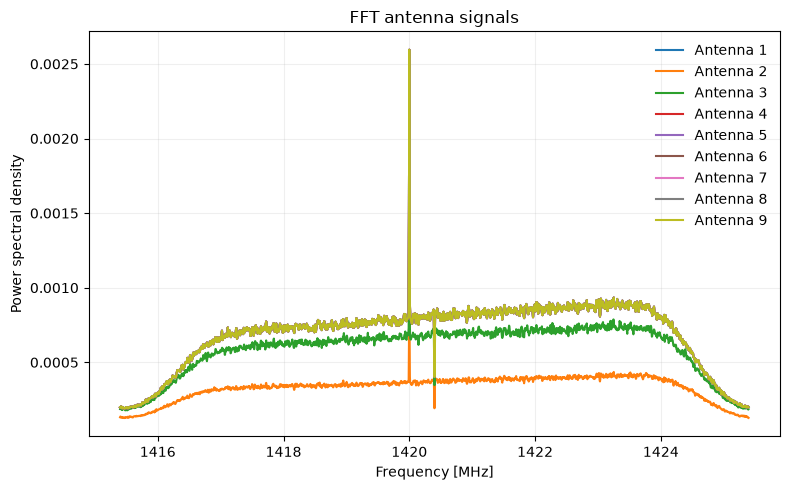

In [6]:
# Plot FFT
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title('FFT antenna signals')
for antenna in range(num_antennas):
    ax.plot(freq, np.real(power_spectra[antenna, :]), label=f'Antenna {antenna+1}')
ax.set_xlabel('Frequency [MHz]')
ax.set_ylabel('Power spectral density')
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

Maximum correlation: (-0.010804603-0.008914354j)
Time delay: 5.1e-06 s
Sample shift: 51


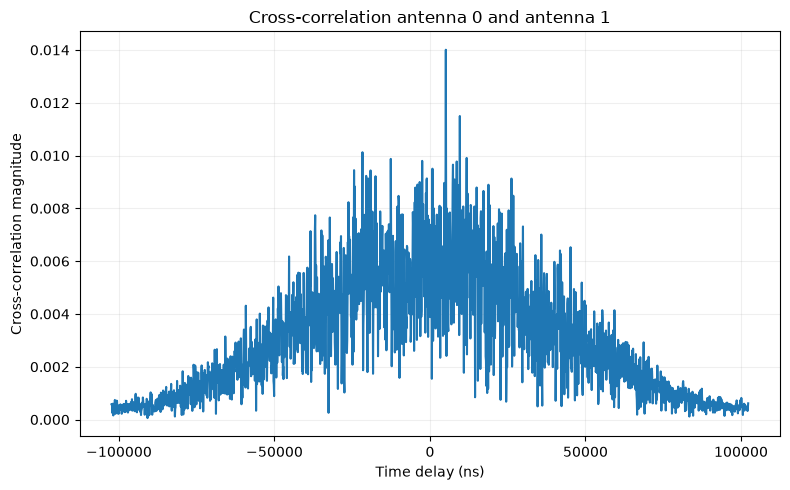

In [7]:
# compute and plot time delay

spectrum1 = fft_data[ANT1]
spectrum2 = fft_data[ANT2]

# cross correlations in frequency domain
block_cross_spectrum = spectrum1 * np.conj(spectrum2)
cross_spectrum = np.mean(block_cross_spectrum, axis=0)

# inverse fft to pass to time domain
cross_spectrum = np.fft.ifftshift(cross_spectrum)
correlations = np.fft.ifft(cross_spectrum)

# Shift zero delay to centre
correlations = np.fft.fftshift(correlations)
# Calculate time delays
time_delays = (np.arange(n_channels) - n_channels // 2) / samp_rate.to(u.Hz).decompose()
# Find maximum correlation
max_index = np.argmax(np.abs(correlations))

print('Maximum correlation:', correlations[max_index])
print('Time delay:', time_delays[max_index])
print('Sample shift:', max_index - n_channels // 2)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.set_title(f'Cross-correlation antenna {ANT1} and antenna {ANT2}')
ax.plot(time_delays * 1e9, np.abs(correlations))
ax.set_xlabel('Time delay (ns)')
ax.set_ylabel('Cross-correlation magnitude')
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

In [8]:
subband = int(((target_freq.value - (central_freq.value - (samp_rate.value//2)))/samp_rate.value)*n_channels)

acm = np.zeros((num_antennas, num_antennas), dtype='complex64')
for ant1 in track(range(num_antennas), description='Computing ACM'):
  for ant2 in range(ant1, num_antennas):
    freq, cross_corr = csd(data[ant1], data[ant2], fs=samp_rate, nperseg=n_channels, return_onesided=False)
    acm[ant1, ant2] = cross_corr[subband]

    if ant1 != ant2:
      acm[ant2, ant1] = np.conj(cross_corr[subband]) # property of frequency domain cross-correlation, saves time

print('ACM generated successfully!')

Output()

ACM generated successfully!


Output()

Number of pixels should be 24


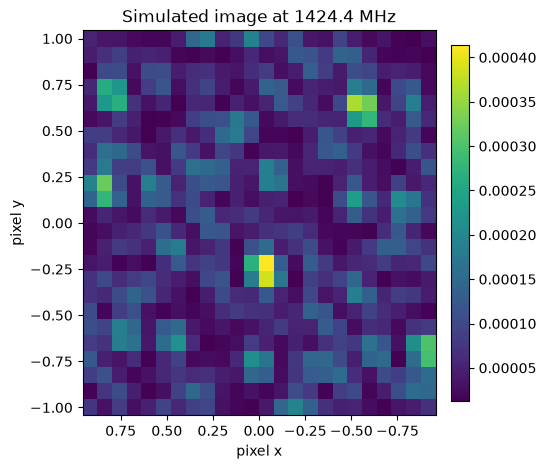

In [9]:
# Make and plot image
fwhm =  ((c.c/target_freq)/(largest_baseline)).decompose()*u.rad
sky_coverage = 2*u.rad
num_pix = int(sky_coverage / (fwhm/2.5))
print(f"Number of pixels should be {num_pix}")

obs_num = 0

img, extent = make_image(acm[:, :], num_pix, uv[obs_num, :, :, :], target_freq)

# Plot image
fig, ax = plt.subplots(figsize=(5, 5))

im = ax.imshow(np.abs(img), origin='lower', extent=extent)

ax.set_title(f"Simulated image at {target_freq:.1f}")
ax.set_xlabel("pixel x")
ax.set_ylabel("pixel y")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.show()
